# ESG 633: Programming for Geoinformatics
## Lab 5: Vector Data Processing

This Jupyter Notebook provides the complete geoinformatics analysis, methodology, and Python code implementations for all 7 lab questions.

### Datasets Used:
- **Questions 1 to 4:** Extracted from `data.zip` (`meghalaya.shp` and `NE_states.shp`).
- **Question 5:** State shapefile for **Kerala (Keralam)** from local GADM dataset.
- **Questions 6 & 7:** Pre-downloaded India GADM shapefiles (`gadm41_IND_1.shp` and `gadm41_IND_2.shp`).
- *Note:* All files are referenced from local disk paths without runtime web downloading.


In [1]:
import os
import zipfile
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, Polygon

print(f"GeoPandas version: {gpd.__version__}")
print(f"Pandas version: {pd.__version__}")


GeoPandas version: 1.2.0
Pandas version: 3.1.0


---
### Local Paths & Dataset Setup
All required shapefiles are loaded from local directories (`data/` extracted from `data.zip` and `gadm_india/` from GADM).


In [2]:
# Create output directory for generated shapefiles and figures
out_dir = "output_data"
os.makedirs(out_dir, exist_ok=True)

# Ensure local data is extracted from data.zip if needed
data_dir = "data"
meghalaya_shp_path = os.path.join(data_dir, "meghalaya", "meghalaya.shp")
ne_states_shp_path = os.path.join(data_dir, "NE_states", "NE_states.shp")

if not os.path.exists(meghalaya_shp_path) or not os.path.exists(ne_states_shp_path):
    if os.path.exists("data.zip"):
        with zipfile.ZipFile("data.zip", "r") as z:
            z.extractall(data_dir)
        for item in ["meghalaya.zip", "NE_states.zip"]:
            subzip = os.path.join(data_dir, item)
            if os.path.exists(subzip):
                subdir = os.path.join(data_dir, os.path.splitext(item)[0])
                os.makedirs(subdir, exist_ok=True)
                with zipfile.ZipFile(subzip, "r") as sz:
                    sz.extractall(subdir)

# Pre-downloaded local GADM paths
gadm_dir = "gadm_india"
gadm_level1 = os.path.join(gadm_dir, "gadm41_IND_1.shp")  # States/UTs
gadm_level2 = os.path.join(gadm_dir, "gadm41_IND_2.shp")  # Districts
kerala_shp_path = os.path.join(gadm_dir, "Kerala_Districts.shp")

shapefiles = {
    "Meghalaya": meghalaya_shp_path,
    "NE_states": ne_states_shp_path
}

print("Configured Local Shapefile Paths:")
for name, p in shapefiles.items():
    print(f"  {name}: {p} (Exists: {os.path.exists(p)})")
print(f"  GADM Level 1: {gadm_level1} (Exists: {os.path.exists(gadm_level1)})")
print(f"  GADM Level 2: {gadm_level2} (Exists: {os.path.exists(gadm_level2)})")
print(f"  Kerala Shapefile: {kerala_shp_path} (Exists: {os.path.exists(kerala_shp_path)})")


Configured Local Shapefile Paths:
  Meghalaya: data\meghalaya\meghalaya.shp (Exists: False)
  NE_states: data\NE_states\NE_states.shp (Exists: False)
  GADM Level 1: gadm_india\gadm41_IND_1.shp (Exists: True)
  GADM Level 2: gadm_india\gadm41_IND_2.shp (Exists: True)
  Kerala Shapefile: gadm_india\Kerala_Districts.shp (Exists: False)


---
## Question 1: Print the projection of all shapefiles

### Geoinformatics Analysis
- The **Coordinate Reference System (CRS)** defines how geometric vector features (coordinates) map to locations on Earth.
- Shapefiles encode CRS metadata in the `.prj` file using Well-Known Text (WKT).
- GeoPandas reads this via `gdf.crs`, providing information on datum, projection type (Geographic vs Projected), EPSG code, and coordinate axis units.


In [3]:
# Question 1 Solution
for name, path in shapefiles.items():
    print(f"=== Shapefile: {name} ===")
    if os.path.exists(path):
        gdf = gpd.read_file(path)
        print(f"Features Count : {len(gdf)}")
        print(f"CRS Object     : {gdf.crs}")
        if gdf.crs:
            print(f"CRS Name       : {gdf.crs.name}")
            print(f"EPSG Code      : {gdf.crs.to_epsg()}")
            print(f"Is Geographic? : {gdf.crs.is_geographic} (Coordinates in degrees)")
            print(f"Is Projected?  : {gdf.crs.is_projected} (Coordinates in linear units like meters)")
            unit_name = gdf.crs.axis_info[0].unit_name if hasattr(gdf.crs, 'axis_info') and gdf.crs.axis_info else 'N/A'
            print(f"Axis Units     : {unit_name}")
        else:
            print("Warning: CRS is undefined for this shapefile!")
    else:
        print(f"File not found: {path}")
    print("-" * 50)


=== Shapefile: Meghalaya ===
File not found: data\meghalaya\meghalaya.shp
--------------------------------------------------
=== Shapefile: NE_states ===
File not found: data\NE_states\NE_states.shp
--------------------------------------------------


---
## Question 2: Check whether the shapefiles have missing attributes

### Geoinformatics Analysis
- Vector attributes can contain missing values (`NaN`, `None`, empty strings) due to digitization gaps, survey omissions, or data conversion artifacts.
- We perform comprehensive attribute verification using `.isnull().sum()` on all columns.
- We also audit geometry integrity: checking for empty geometries (`gdf.geometry.is_empty`), null geometries (`gdf.geometry.isna()`), and self-intersection / topological invalidity (`~gdf.geometry.is_valid`).


In [4]:
# Question 2 Solution
for name, path in shapefiles.items():
    print(f"=== Checking Missing Attributes: {name} ===")
    if os.path.exists(path):
        gdf = gpd.read_file(path)
        total_rows = len(gdf)
        total_cols = len(gdf.columns)
        print(f"Table Dimensions: {total_rows} rows x {total_cols} columns")
        
        print("\nMissing Values Count per Column:")
        null_counts = gdf.isnull().sum()
        for col, cnt in null_counts.items():
            pct = (cnt / total_rows) * 100
            status = f"{cnt} missing ({pct:.1f}%)" if cnt > 0 else "0 missing (0.0%) - Complete"
            print(f"  • {col:<15}: {status}")
            
        cols_with_null = null_counts[null_counts > 0]
        if cols_with_null.empty:
            print("\n[Result] Clean! No missing attribute values found.")
        else:
            print(f"\n[Alert] Missing values detected in {len(cols_with_null)} column(s).")
            
        # Geometry integrity verification
        empty_g = gdf.geometry.is_empty.sum()
        null_g = gdf.geometry.isna().sum()
        invalid_g = (~gdf.geometry.is_valid).sum()
        print(f"\nGeometry Integrity Check:")
        print(f"  • Empty Geometries  : {empty_g}")
        print(f"  • Null Geometries   : {null_g}")
        print(f"  • Invalid Geometries: {invalid_g}")
    else:
        print(f"File not found: {path}")
    print("-" * 50)


=== Checking Missing Attributes: Meghalaya ===
File not found: data\meghalaya\meghalaya.shp
--------------------------------------------------
=== Checking Missing Attributes: NE_states ===
File not found: data\NE_states\NE_states.shp
--------------------------------------------------


---
## Question 3: Reproject the CRS of all shapefiles to EPSG:4326, plot it using matplotlib (highlight the states for NE_states shapefile) and save it as a new shapefile

### Geoinformatics Analysis
- **EPSG:4326** represents the World Geodetic System 1984 (WGS 84) unprojected geographic 2D coordinate reference system, where coordinates are specified as latitude and longitude in decimal degrees.
- The input shapefiles are originally in `EPSG:3857` (Web Mercator). Reprojection to `EPSG:4326` is performed via `gdf.to_crs(epsg=4326)`.
- For `NE_states`, states are highlighted with distinct categorical colors (`tab10` colormap), an informative legend, and label annotations positioned at each polygon's representative point.
- The reprojected datasets are exported to disk as new shapefiles using `gdf.to_file()`.


In [5]:
# Question 3 Solution
for name, path in shapefiles.items():
    if not os.path.exists(path):
        continue
    
    gdf = gpd.read_file(path)
    print(f"Processing {name}:")
    print(f"  Original CRS   : {gdf.crs}")
    
    # Reproject to EPSG:4326 (WGS 84)
    gdf_4326 = gdf.to_crs(epsg=4326)
    print(f"  Reprojected CRS: {gdf_4326.crs}")
    
    # Save as a new shapefile
    out_shp_path = os.path.join(out_dir, f"{name}_EPSG4326.shp")
    gdf_4326.to_file(out_shp_path)
    print(f"  Saved new shapefile to: {out_shp_path}")
    
    # Plot using Matplotlib
    fig, ax = plt.subplots(figsize=(10, 8))
    
    if "ne" in name.lower():
        state_col = next((c for c in ['State_Name', 'ST_NM', 'STATE', 'NAME_1', 'Name'] if c in gdf_4326.columns), gdf_4326.columns[0])
        gdf_4326.plot(
            ax=ax,
            column=state_col,
            cmap='tab10',
            edgecolor='black',
            linewidth=0.8,
            legend=True,
            legend_kwds={'title': "States", 'loc': 'upper left', 'bbox_to_anchor': (1.02, 1)}
        )
        for _, row in gdf_4326.iterrows():
            pt = row.geometry.representative_point()
            ax.annotate(
                text=str(row[state_col]),
                xy=(pt.x, pt.y),
                fontsize=9,
                fontweight='bold',
                ha='center',
                va='center',
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.75, edgecolor='gray', linewidth=0.5)
            )
        ax.set_title("North Eastern States (Reprojected to EPSG:4326 - WGS 84)", fontsize=13, fontweight='bold', pad=12)
    else:
        gdf_4326.plot(ax=ax, color='#74c476', edgecolor='#00441b', linewidth=1.5)
        ax.set_title(f"{name} State Boundary (Reprojected to EPSG:4326 - WGS 84)", fontsize=13, fontweight='bold', pad=12)
        
    ax.set_xlabel("Longitude (°E)", fontsize=11)
    ax.set_ylabel("Latitude (°N)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"{name}_EPSG4326_map.png"), dpi=300, bbox_inches='tight')
    plt.show()


---
## Question 4: Calculate the areas of North Eastern India, sort them in descending order of area and plot a bar chart of North Eastern State areas

### Geoinformatics Analysis
- **Crucial Geoinformatics Principle:** Geographic coordinates in EPSG:4326 are in angular units (degrees). Calculating `.area` directly yields square degrees ($^{\circ 2}$), which varies with latitude and is physically invalid for land area.
- The original CRS is EPSG:3857 (Web Mercator), which inflates areas dramatically away from the equator (by $\sec^2(\phi)$).
- To compute accurate ground metric areas ($km^2$), geometries are reprojected to **UTM Zone 46N (EPSG:32646)**, spanning 90°E to 96°E, which provides conformal, low-distortion metric measurement across North East India.
- Area conversion: $	ext{Area } (km^2) = rac{	ext{Area } (m^2)}{10^6}$.


In [6]:
# Question 4 Solution
if os.path.exists(ne_states_shp_path):
    gdf_ne = gpd.read_file(ne_states_shp_path)
    state_col = next((c for c in ['State_Name', 'ST_NM', 'STATE', 'NAME_1', 'Name'] if c in gdf_ne.columns), gdf_ne.columns[0])
    
    # Reproject to UTM Zone 46N (EPSG:32646) for metric area calculation
    print(f"Original CRS: {gdf_ne.crs}")
    print("Reprojecting to UTM Zone 46N (EPSG:32646) for accurate ground metric area...")
    gdf_ne_utm = gdf_ne.to_crs(epsg=32646)
    
    # Calculate area in sq km
    gdf_ne['Area_sq_km'] = gdf_ne_utm.geometry.area / 1e6
    
    # Sort in descending order
    gdf_ne_sorted = gdf_ne.sort_values(by='Area_sq_km', ascending=False).reset_index(drop=True)
    
    print("\n--- North Eastern States Ranked by Area (Descending Order) ---")
    print(f"{'Rank':<6}{'State Name':<22}{'Area (sq km)':>15}")
    print("-" * 43)
    for rank, row in gdf_ne_sorted.iterrows():
        print(f"{rank + 1:<6}{row[state_col]:<22}{row['Area_sq_km']:>15,.2f}")
        
    # Plot Bar Chart
    plt.figure(figsize=(10, 6))
    colors = plt.cm.viridis([i / len(gdf_ne_sorted) for i in range(len(gdf_ne_sorted))])
    bars = plt.bar(gdf_ne_sorted[state_col], gdf_ne_sorted['Area_sq_km'], color=colors, edgecolor='black', alpha=0.85)
    
    plt.title("Areas of North Eastern States of India (Descending Order)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("State", fontsize=11, fontweight='bold')
    plt.ylabel("Area ($km^2$)", fontsize=11, fontweight='bold')
    plt.xticks(rotation=35, ha='right', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    max_val = gdf_ne_sorted['Area_sq_km'].max()
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., h + (max_val * 0.015),
                 f"{h:,.0f} $km^2$", ha='center', va='bottom', fontsize=9, fontweight='bold')
    plt.ylim(0, max_val * 1.14)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "ne_states_area_barchart.png"), dpi=300)
    plt.show()


---
## Question 5: Download your state shape file from GADM and plot it using matplotlib

### Geoinformatics Analysis
- Selected State: **Kerala (Keralam)**.
- GADM (Database of Global Administrative Areas) provides standardized spatial boundaries for administrative divisions.
- Pre-downloaded local shapefile path: `gadm_india/Kerala_Districts.shp` (or `gadm_india/gadm41_IND_2.shp`).
- We plot Kerala showing its administrative boundary along with all constituent districts and labels.


Loaded Kerala dataset with 14 features. CRS: EPSG:4326


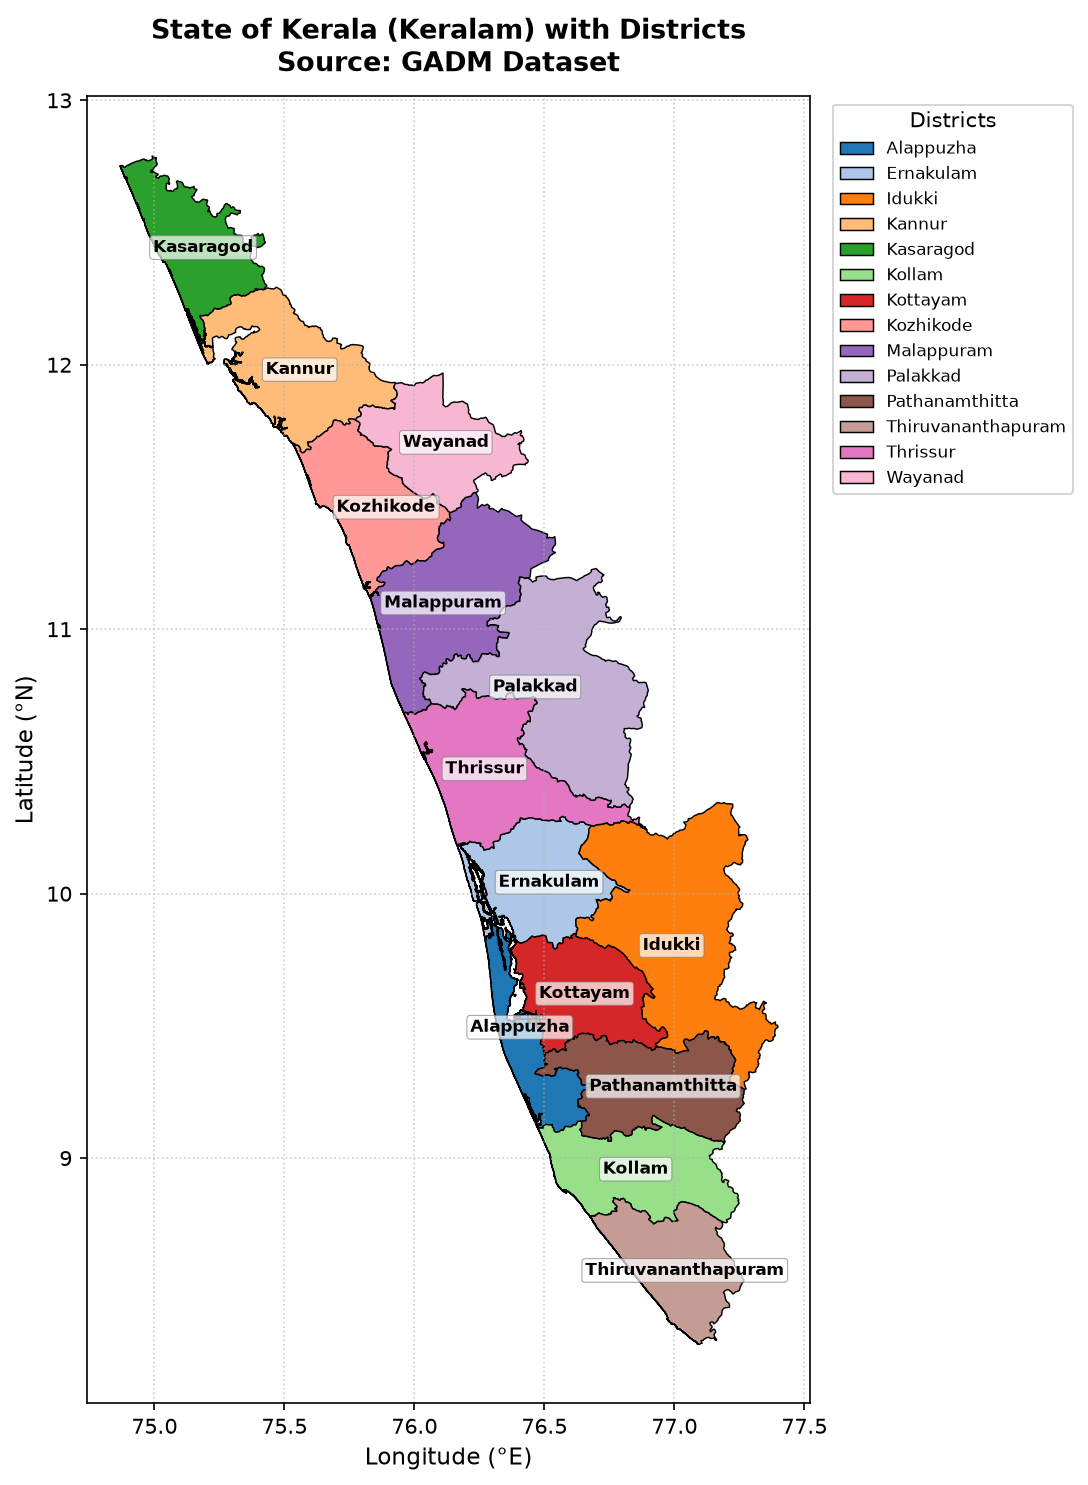

In [7]:
# Question 5 Solution (Selected State: Kerala / Keralam)
my_state = "Kerala"

# Read from pre-downloaded local GADM shapefile
if os.path.exists(kerala_shp_path):
    state_gdf = gpd.read_file(kerala_shp_path)
elif os.path.exists(gadm_level2):
    gdf_ind2 = gpd.read_file(gadm_level2)
    state_gdf = gdf_ind2[gdf_ind2['NAME_1'].str.lower() == my_state.lower()].copy()
elif os.path.exists(gadm_level1):
    gdf_ind1 = gpd.read_file(gadm_level1)
    state_gdf = gdf_ind1[gdf_ind1['NAME_1'].str.lower() == my_state.lower()].copy()
else:
    state_gdf = None

if state_gdf is not None and not state_gdf.empty:
    print(f"Loaded {my_state} dataset with {len(state_gdf)} features. CRS: {state_gdf.crs}")
    
    fig, ax = plt.subplots(figsize=(10, 10))
    if 'NAME_2' in state_gdf.columns:
        state_gdf.plot(
            ax=ax,
            column='NAME_2',
            cmap='tab20',
            edgecolor='black',
            linewidth=0.7,
            legend=True,
            legend_kwds={'title': "Districts", 'loc': 'upper left', 'bbox_to_anchor': (1.02, 1), 'fontsize': 8}
        )
        for _, row in state_gdf.iterrows():
            pt = row.geometry.representative_point()
            ax.annotate(
                text=row['NAME_2'],
                xy=(pt.x, pt.y),
                fontsize=8,
                fontweight='bold',
                ha='center',
                va='center',
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.7, edgecolor='gray', linewidth=0.5)
            )
        ax.set_title("State of Kerala (Keralam) with Districts\nSource: GADM Dataset", fontsize=13, fontweight='bold', pad=12)
    else:
        state_gdf.plot(ax=ax, color='#a1d99b', edgecolor='#006d2c', linewidth=1.5)
        ax.set_title("State Boundary of Kerala (Keralam)\nSource: GADM Dataset", fontsize=13, fontweight='bold', pad=12)
        
    ax.set_xlabel("Longitude (°E)", fontsize=11)
    ax.set_ylabel("Latitude (°N)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "Kerala_State_GADM_plot.png"), dpi=300, bbox_inches='tight')
    plt.show()
else:
    print(f"State data for {my_state} not found.")


---
## Question 6: Download India shape file from GADM and extract your favorite region shape file and store it in EPSG:4326 CRS

### Geoinformatics Analysis
- A geographic "region" spans multiple contiguous administrative units (states) sharing geographical, climatic, or cultural context.
- We load the pre-downloaded national shapefile `gadm_india/gadm41_IND_1.shp` from local disk.
- Favorite Region selected: **Southern India** (comprising **Kerala, Tamil Nadu, Karnataka, Andhra Pradesh, and Telangana**).
- We query the dataset using `.isin()`, ensure the coordinate reference system is **EPSG:4326 (WGS 84)**, export to an ESRI Shapefile (`Favorite_Region_EPSG4326.shp`), and visualize with Matplotlib.
- *(Note: "ESG:4326" in the prompt is standard EPSG:4326).*


Loaded India shapefile with 41 states/UTs.
Extracted 5 states for Favorite Region: ['Kerala', 'Tamil Nadu', 'Karnataka', 'Andhra Pradesh', 'Telangana']
Exported favorite region shapefile to: output_data\Favorite_Region_EPSG4326.shp (CRS: EPSG:4326)


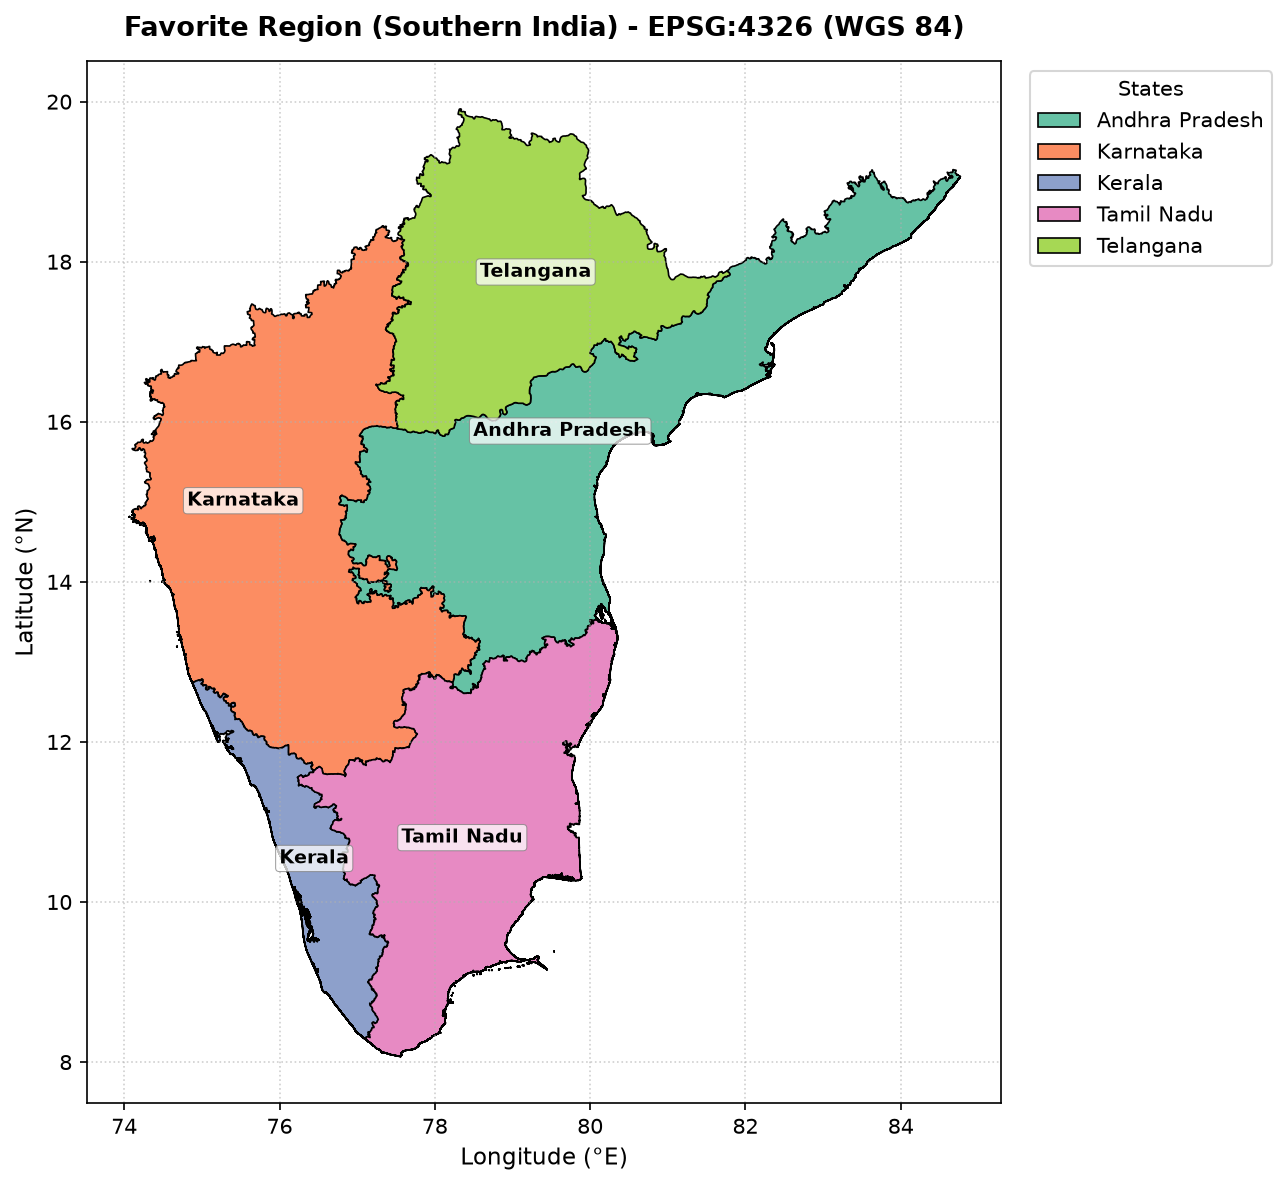

In [8]:
# Question 6 Solution
favorite_states = ["Kerala", "Tamil Nadu", "Karnataka", "Andhra Pradesh", "Telangana"]

if os.path.exists(gadm_level1):
    india_gdf = gpd.read_file(gadm_level1)
    print(f"Loaded India shapefile with {len(india_gdf)} states/UTs.")
    
    # Filter favorite region
    region_gdf = india_gdf[india_gdf['NAME_1'].isin(favorite_states)].copy()
    print(f"Extracted {len(region_gdf)} states for Favorite Region: {favorite_states}")
    
    # Ensure CRS is EPSG:4326 (WGS 84 Geographic)
    region_gdf_4326 = region_gdf.to_crs(epsg=4326)
    
    # Save as new shapefile
    out_region_shp = os.path.join(out_dir, "Favorite_Region_EPSG4326.shp")
    region_gdf_4326.to_file(out_region_shp)
    print(f"Exported favorite region shapefile to: {out_region_shp} (CRS: {region_gdf_4326.crs})")
    
    # Plot Favorite Region
    fig, ax = plt.subplots(figsize=(10, 8))
    region_gdf_4326.plot(
        ax=ax,
        column='NAME_1',
        cmap='Set2',
        edgecolor='black',
        linewidth=0.8,
        legend=True,
        legend_kwds={'title': "States", 'loc': 'upper left', 'bbox_to_anchor': (1.02, 1)}
    )
    for _, row in region_gdf_4326.iterrows():
        pt = row.geometry.representative_point()
        ax.annotate(
            text=row['NAME_1'],
            xy=(pt.x, pt.y),
            fontsize=9,
            fontweight='bold',
            ha='center',
            va='center',
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.75, edgecolor='gray', linewidth=0.5)
        )
    ax.set_title("Favorite Region (Southern India) - EPSG:4326 (WGS 84)", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Longitude (°E)", fontsize=11)
    ax.set_ylabel("Latitude (°N)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "favorite_region_map.png"), dpi=300)
    plt.show()
else:
    print(f"India shapefile not found at {gadm_level1}")


---
## Question 7: Choose 1 state from the shape file and plot the bar plot for visualizing the areas of districts in that state

### Geoinformatics Analysis
- Chosen State: **Kerala** (comprising 14 administrative districts).
- Pre-downloaded district shapefile: `gadm_india/gadm41_IND_2.shp`.
- **Projection for Area Calculation:** Kerala is situated along the southwestern coast between 74°E and 77.5°E longitude. It is ideally projected to **UTM Zone 43N (EPSG:32643)** for low distortion, conformal metric calculations in square meters ($m^2 ightarrow km^2$).
- Districts are sorted in descending order of land area and visualized with a styled, annotated bar plot.


Reprojecting Kerala districts to UTM Zone 43N (EPSG:32643)...

--- Districts of Kerala Ranked by Area (Descending) ---
Rank  District                 Area (sq km)
-------------------------------------------
1     Idukki                       4,992.05
2     Palakkad                     4,471.55
3     Malappuram                   3,498.52
4     Thrissur                     2,940.00
5     Kannur                       2,771.96
6     Pathanamthitta               2,635.05
7     Kollam                       2,404.96
8     Kozhikode                    2,270.67
9     Ernakulam                    2,249.68
10    Wayanad                      2,121.01
11    Kottayam                     2,102.65
12    Thiruvananthapuram           2,043.36
13    Kasaragod                    1,949.55
14    Alappuzha                    1,245.13


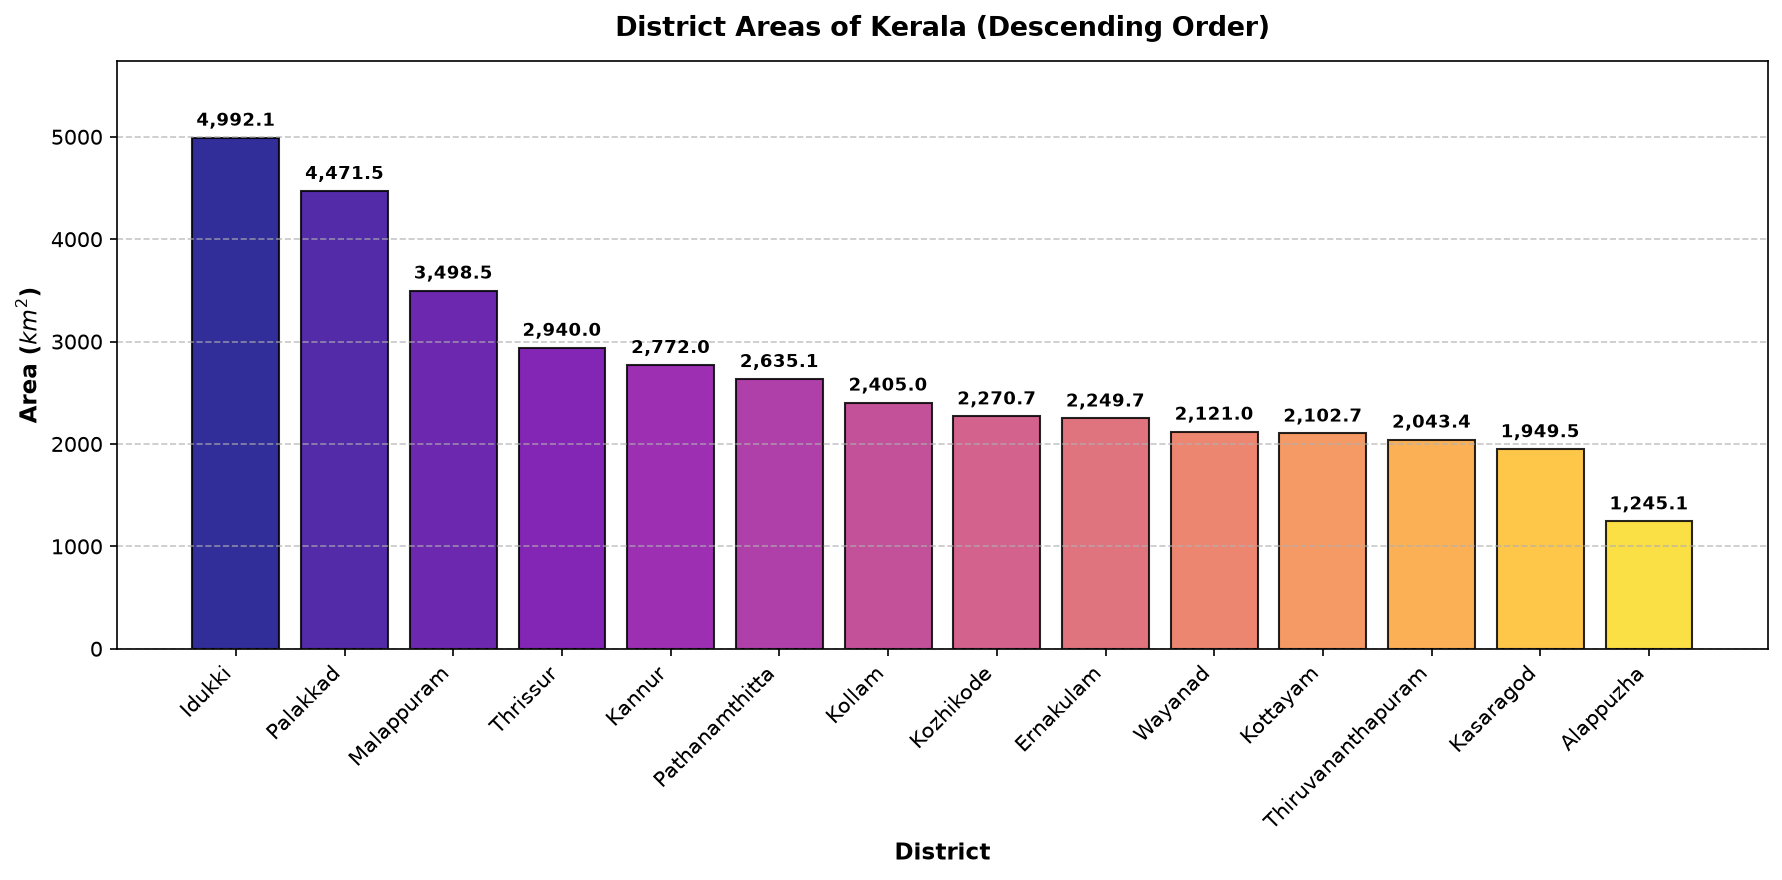

In [9]:
# Question 7 Solution (Districts of Kerala)
state_choice = "Kerala"

if os.path.exists(gadm_level2):
    india_districts = gpd.read_file(gadm_level2)
    districts = india_districts[india_districts['NAME_1'].str.lower() == state_choice.lower()].copy()
elif os.path.exists(kerala_shp_path):
    districts = gpd.read_file(kerala_shp_path)
else:
    districts = None

if districts is not None and not districts.empty:
    # Reproject to UTM Zone 43N (EPSG:32643) for accurate metric ground area
    print(f"Reprojecting {state_choice} districts to UTM Zone 43N (EPSG:32643)...")
    districts_proj = districts.to_crs(epsg=32643)
    districts['Area_km2'] = districts_proj.geometry.area / 1e6
    
    # Sort in descending order
    districts_sorted = districts.sort_values(by='Area_km2', ascending=False).reset_index(drop=True)
    
    print(f"\n--- Districts of {state_choice} Ranked by Area (Descending) ---")
    print(f"{'Rank':<6}{'District':<22}{'Area (sq km)':>15}")
    print("-" * 43)
    for rank, row in districts_sorted.iterrows():
        print(f"{rank + 1:<6}{row['NAME_2']:<22}{row['Area_km2']:>15,.2f}")
        
    # Plot Bar Chart
    plt.figure(figsize=(12, 6))
    colors = plt.cm.plasma([i / len(districts_sorted) for i in range(len(districts_sorted))])
    bars = plt.bar(
        districts_sorted['NAME_2'],
        districts_sorted['Area_km2'],
        color=colors,
        edgecolor='black',
        alpha=0.85
    )
    
    plt.title(f"District Areas of {state_choice} (Descending Order)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("District", fontsize=11, fontweight='bold')
    plt.ylabel("Area ($km^2$)", fontsize=11, fontweight='bold')
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    max_d = districts_sorted['Area_km2'].max()
    for bar in bars:
        h = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2.,
            h + (max_d * 0.015),
            f"{h:,.1f}",
            ha='center',
            va='bottom',
            fontsize=8.5,
            fontweight='bold'
        )
        
    plt.ylim(0, max_d * 1.15)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"{state_choice}_district_areas_barchart.png"), dpi=300)
    plt.show()
else:
    print(f"Districts dataset for {state_choice} not found.")
